In [ ]:
pip install pandas geopandas

In [ ]:
!pip install folium

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import time
import json
import folium
from folium.plugins import HeatMap
import branca.colormap as cm
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 추정교통량 데이터 로드
estimTraffic = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_추정교통량.csv')

# 기존 칼럼명과 새로운 칼럼명 매칭 딕셔너리 생성
column_mappings = {
    'year': '기준연도',
    'link_id': '도로ID',
    'road_rank': '도로등급',
    'road_length': '도로링크길이',
    'road_nm': '도로명',
    'sido_nm': '시도명',
    'sgg_nm': '시군구명',
    'emd_nm': '읍면동명',
    'timeslot': '측정시간정보',
    'ALL_AADT': '전체추정치',
    'PSCR_AADT': '승용차추정치',
    'BUS_AADT': '버스추정치',
    'FGCR_AADT': '화물차추정치'
}

<ipython-input-4-8ff9d0675a9b>:18: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  estimTraffic = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_추정교통량.csv')


In [ ]:
"""
# 칼럼명 변경
estimTraffic.rename(columns=column_mappings, inplace=True)

# 필요한 칼럼 선택
df = estimTraffic[['도로ID', '도로링크길이', '시도명', '시군구명', '읍면동명', '도로명']]

# 특정 범위의 데이터 선택
df_subset = df.iloc[938008:938507]

# 위도, 경도 저장할 리스트
coordinates = []

# 성공한 User-Agent
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/14.1.2 Safari/605.1.15'
}

# Nominatim API를 사용하여 위도와 경도 찾기
for index, row in df_subset.iterrows():
    address = f"{row['시도명']} {row['시군구명']} {row['읍면동명']}"
    print(f"Fetching coordinates for: {address}")

    # Nominatim API 요청
    response = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={'q': address, 'format': 'json', 'addressdetails': 1},
        headers=headers
    )

    if response.status_code == 200:
        results = response.json()
        if results:
            lat = results[0]['lat']
            lng = results[0]['lon']
            coordinates.append((lat, lng))
            print(f"Found coordinates: {lat}, {lng}")
        else:
            coordinates.append((None, None))
            print(f"No results found for: {address}")
    else:
        coordinates.append((None, None))
        print(f"Error {response.status_code} for: {address}")

    # 작은 지연 시간을 추가하여 API 요청 과부하 방지
    time.sleep(1)

# 데이터프레임에 위도, 경도 추가
df['latitude'] = [lat if lat is not None else float('nan') for lat, _ in coordinates]
df['longitude'] = [lng if lng is not None else float('nan') for _, lng in coordinates]

# 결과 확인
print("All Coordinates:")
print(df)
"""

Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동
Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동
Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동
Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동
Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동
Fetching coordinates for: 경기도 화성시 동탄2동
No results found for: 경기도 화성시 동탄2동


KeyboardInterrupt: 

In [ ]:
# 다양한 User-Agent 시도
user_agents = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:91.0) Gecko/20100101 Firefox/91.0',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/14.1.2 Safari/605.1.15'
]

# 테스트할 주소
address = "서울특별시 강남구 역삼동"
url = "https://nominatim.openstreetmap.org/search"
params = {'q': address, 'format': 'json', 'addressdetails': 1}

for ua in user_agents:
    headers = {'User-Agent': ua}
    response = requests.get(url, params=params, headers=headers)
    print(f"Trying User-Agent: {ua}")
    print(f"Status Code: {response.status_code}")
    if response.status_code == 200:
        results = response.json()
        print(json.dumps(results, indent=2, ensure_ascii=False))
        break
    else:
        print(f"Error: {response.status_code}")
"""

Trying User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:91.0) Gecko/20100101 Firefox/91.0
Status Code: 403
Error: 403
Trying User-Agent: Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.36
Status Code: 403
Error: 403
Trying User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36
Status Code: 403
Error: 403
Trying User-Agent: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/14.1.2 Safari/605.1.15
Status Code: 200
[
  {
    "place_id": 228056676,
    "licence": "Data © OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright",
    "osm_type": "node",
    "osm_id": 415155292,
    "lat": "37.49988",
    "lon": "127.03856",
    "class": "place",
    "type": "quarter",
    "place_rank": 20,
    "importance": 0.13340631342030973,
    "addresstype": "quarter",
    "name": "역삼동",
    "display_name": "역삼동, 역삼2동

In [ ]:
df = pd.DataFrame(estimTraffic)

# 특정 범위의 데이터 선택
df_subset = df.iloc[938008:938508]

# 위도, 경도 정보를 저장할 열을 미리 생성
df['위도'] = None
df['경도'] = None

# 읍면동 이름에 맞는 위도, 경도 정보를 사전으로 저장
location_data = {
    '동탄1동': (37.2110798,127.0735232671266),
    '동탄2동': (37.1919635, 127.07407968704996),
    '동탄3동': (37.2100305,127.0589014),
    '동탄4동': (37.1994688,127.1123608),
    '동탄5동': (37.2100222,127.1039464),
    '동탄6동': (37.1912925,127.0901262),
    '동탄7동': (37.1706048,127.1100395)
}

# 각 행을 순회하며 위도와 경도 값을 추가
for idx, row in df.iterrows():
    name = row['읍면동명']
    if name in location_data:
        df.at[idx, '위도'] = location_data[name][0]
        df.at[idx, '경도'] = location_data[name][1]

# 결과 출력
print(df.loc[938008:938508])

df_subset = df.iloc[938008:938513].copy()

# 수정된 데이터를 원래 데이터프레임에 덮어쓰기
estimTraffic2 = df_subset

# 결과 확인
print(estimTraffic2)

# 필요에 따라 CSV 파일로 저장
estimTraffic2.to_csv("estimTraffic2.csv", index=False)


        기준연도         도로ID  도로등급  도로링크길이     도로명  시도명 시군구명  읍면동명 측정시간정보  전체추정치  \
938008  2020  57137101401   107   0.115   동탄나루로  경기도  화성시  동탄2동     19    306   
938009  2020  57137101402   107   0.115   동탄나루로  경기도  화성시  동탄2동     19    368   
938010  2020  57137101501   107   0.135   동탄나루로  경기도  화성시  동탄2동     19    248   
938011  2020  57137101502   107   0.135   동탄나루로  경기도  화성시  동탄2동     19    341   
938012  2020  57137092901   107   0.382  동탄신리천로  경기도  화성시  동탄2동     19    727   
...      ...          ...   ...     ...     ...  ...  ...   ...    ...    ...   
938504  2020  57137068701   107   0.112     NaN  경기도  화성시  동탄7동     19     89   
938505  2020  57137068702   107   0.112     NaN  경기도  화성시  동탄7동     19    108   
938506  2020  57137121201   107   0.113     NaN  경기도  화성시  동탄7동     19    113   
938507  2020  57137069002   107   0.114     NaN  경기도  화성시  동탄7동     19     86   
938508  2020  57137121101   107   0.115     NaN  경기도  화성시  동탄7동     19    159   

        승용차추정치  버스추정치  화물차추

In [ ]:
# DataFrame 생성
estimTrafficMap = pd.DataFrame(df)
estimTrafficMap = estimTrafficMap.iloc[938008:938508]

# 교통량 구간 나누기 (예: 0-200, 200-400, 400-600, 600-800, 800+)
bins = [0, 200, 400, 600, 800, 1000]
labels = ['0-200', '200-400', '400-600', '600-800', '800+']
estimTrafficMap['volumeCategory'] = pd.cut(estimTrafficMap['전체추정치'], bins, labels=labels)

# 지도 초기화
m = folium.Map(location=[37.566, 126.978], zoom_start=12)

# 컬러 맵 설정 (교통량에 따른 색상 설정)
colormap = cm.LinearColormap(colors=['green', 'yellow', 'red'],
                             vmin=0, vmax=1000,
                             caption='Traffic Volume')

# 각 도로 교통량을 지도로 추가 (교통량 기준으로 색상 설정)
for _, row in estimTrafficMap.iterrows():
    folium.CircleMarker(
        location=[row['위도'], row['경도']],
        radius=5,
        color=colormap(row['전체추정치']),
        fill=True,
        fill_color=colormap(row['전체추정치']),
        fill_opacity=0.7,
        popup=f"Traffic Volume: {row['전체추정치']}"
    ).add_to(m)

# 컬러 맵 추가
colormap.add_to(m)

# 지도를 HTML 파일로 저장
m.save('traffic_map.html')

# 코랩 환경에서 지도를 표시
display(m)


Mean Absolute Error: 301.85906372390144
Mean Squared Error: 149192.81302805227


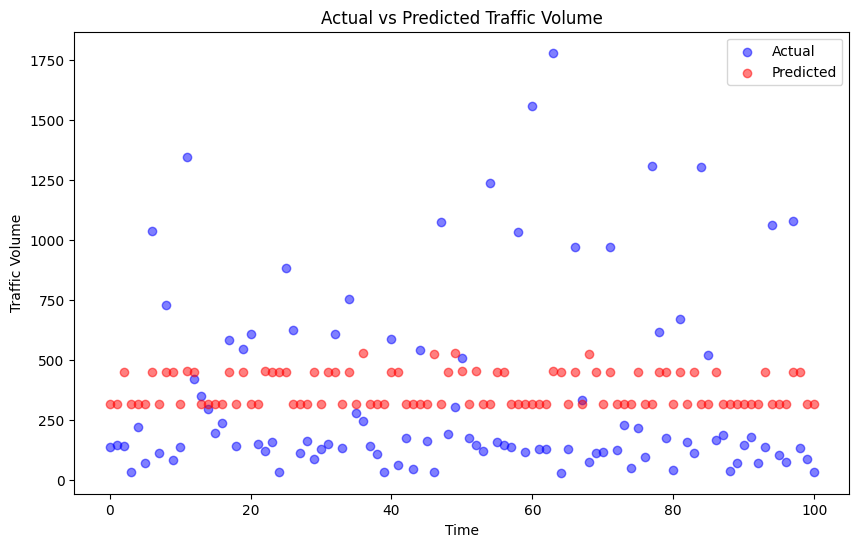

In [ ]:
#읽어오기
estimTraffic2 = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/estimTraffic2.csv')

df = pd.DataFrame(estimTraffic2)

# 사용할 특성과 타깃 변수 선택
features = ['측정시간정보', '위도', '경도']
target = '전체추정치'

# 학습 셋과 테스트 셋으로 분할
X_train, X_test, y_train, y_test = train_test_split(df[features], df[target], test_size=0.2, random_state=42)

# 모델 선택 및 학습 (Linear Regression)
model = LinearRegression()
model.fit(X_train, y_train)

# 예측 및 평가
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")

# 예측 결과 시각화
plt.figure(figsize=(10, 6))  # 그래프 크기 설정
plt.scatter(range(len(y_test)), y_test, color='blue', alpha=0.5, label='Actual')  # 실제 값
plt.scatter(range(len(y_test)), y_pred, color='red', alpha=0.5, label='Predicted')  # 예측 값
plt.legend()
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.title('Actual vs Predicted Traffic Volume')
plt.show()

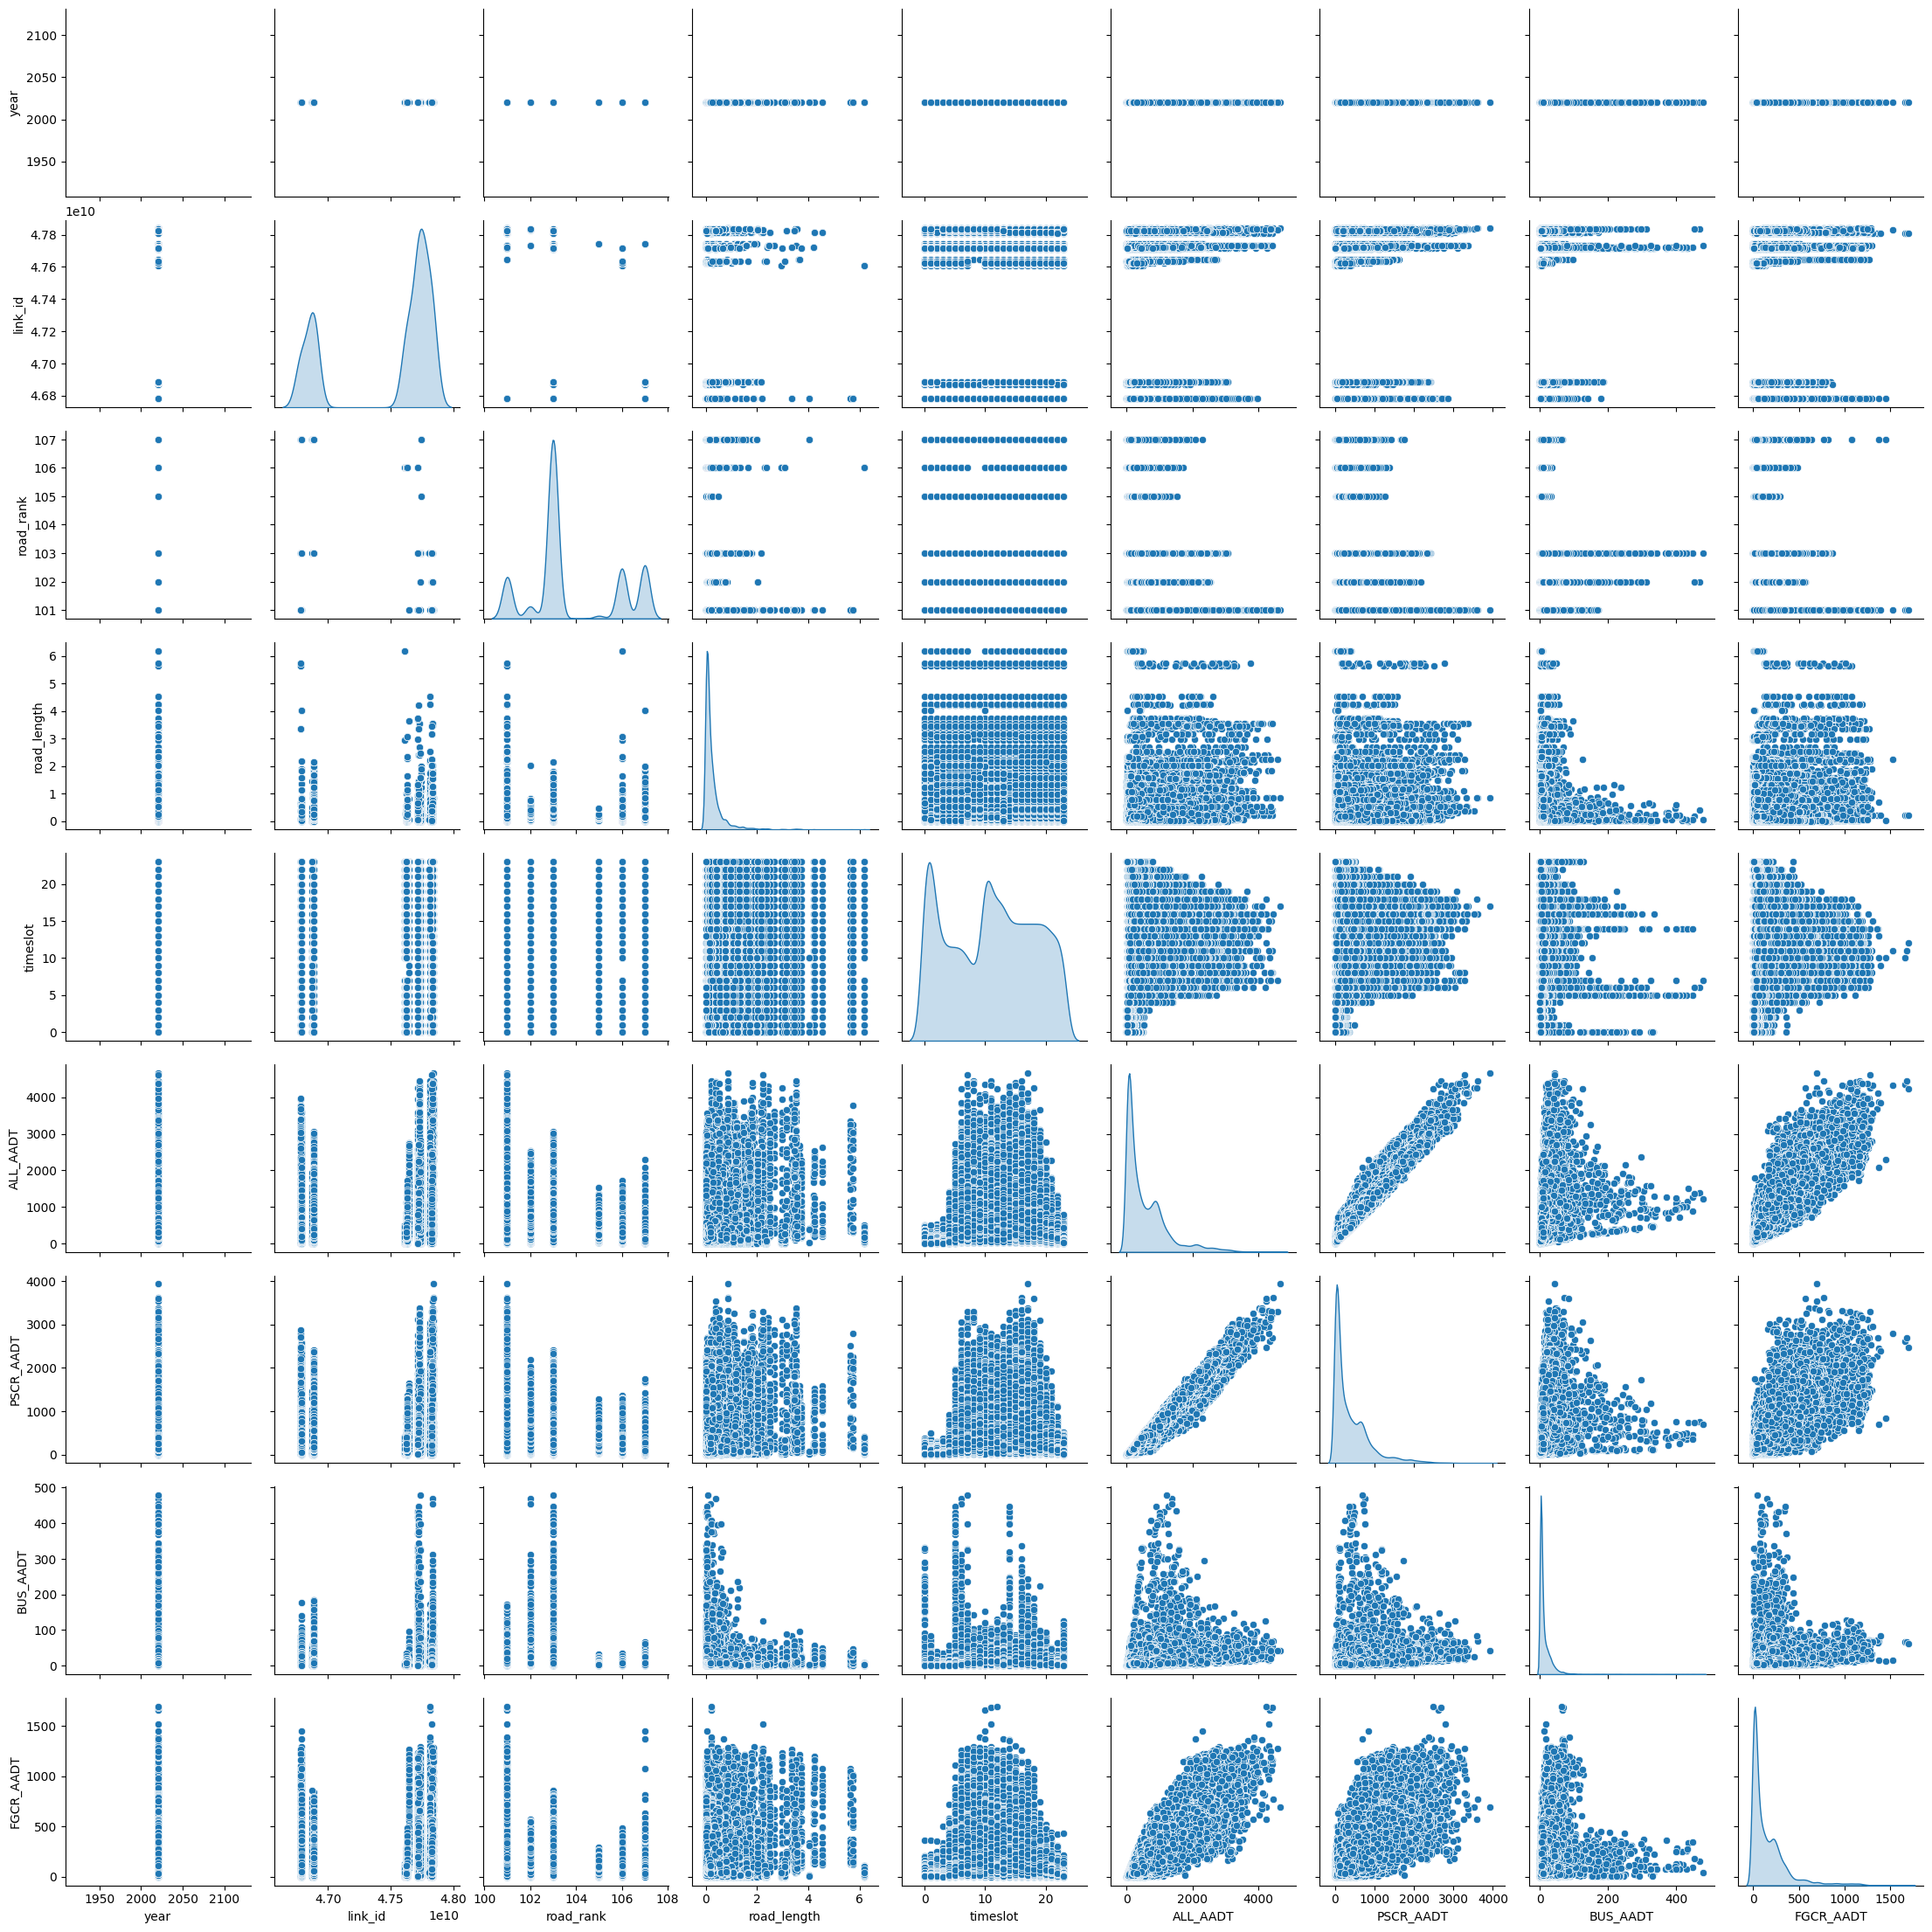

In [ ]:
estimTrafficOriginal = pd.read_csv('/content/오산시_추정교통량.csv')
df = pd.DataFrame(estimTrafficOriginal)

# 데이터 분포 시각화
sns.pairplot(df, diag_kind='kde')
plt.show()

In [ ]:
# 결측치 확인
print(df.isnull().sum())

# 통계적 요약 확인
print(df.describe())

기준연도        0
도로ID        0
도로등급        0
도로링크길이      0
도로명       245
시도명         0
시군구명        0
읍면동명        0
측정시간정보      0
전체추정치       0
승용차추정치      0
버스추정치       0
화물차추정치      0
위도          0
경도          0
dtype: int64
         기준연도          도로ID   도로등급      도로링크길이  측정시간정보        전체추정치  \
count   505.0  5.050000e+02  505.0  505.000000   505.0   505.000000   
mean   2020.0  5.713742e+10  107.0    0.107964    19.0   359.825743   
std       0.0  3.569693e+05    0.0    0.091240     0.0   393.862030   
min    2020.0  5.713707e+10  107.0    0.014000    19.0    29.000000   
25%    2020.0  5.713713e+10  107.0    0.046000    19.0   109.000000   
50%    2020.0  5.713721e+10  107.0    0.088000    19.0   152.000000   
75%    2020.0  5.713768e+10  107.0    0.128000    19.0   532.000000   
max    2020.0  5.713833e+10  107.0    0.777000    19.0  1952.000000   

            승용차추정치       버스추정치      화물차추정치          위도          경도  
count   505.000000  505.000000  505.000000  505.000000  505.000000  

In [ ]:
"""
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import seaborn as sns
import matplotlib.pyplot as plt

# 과속방지턱 데이터 로드
speedBump = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_과속방지턱정보.csv')
# 교통 CCTV 데이터 로드
trafficCctv = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_교통CCTV설치현황.csv')
# 교차로 데이터 로드
crossRoad = gpd.read_file('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_교차로.geojson')
# 횡단보도 데이터 로드
crossWalk = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_횡단보도현황.csv')
# 추정교통량 데이터 로드
estimTraffic = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_추정교통량.csv')
# 신호등 데이터 로드
trafficLight = pd.read_csv('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_신호등현황.csv')
# 상세도로망 데이터 로드
speciRoadMap = gpd.read_file('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_상세도로망.geojson')
# 매핑용 격자 데이터 로드
gridRoad = gpd.read_file('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_격자(매핑용).geojson')
# 교통사고이력 데이터 로드
trafficAccident = gpd.read_file('/content/drive/MyDrive/호파이_여름프로젝트_데이터셋/오산시_교통사고이력.geojson')

# 전처리
# 지리적 좌표를 Point 객체로 변환
speedBump['geometry'] = speedBump.apply(lambda row: Point(row['lon'], row['lat']), axis = 1)
trafficLight['geometry'] = trafficLight.apply(lambda row: Point(row['lon'], row['lat']), axis = 1)
crossWalk['geometry'] = crossWalk.apply(lambda row: Point(row['lon'], row['lat']), axis = 1)
trafficCctv['geometry'] = trafficCctv.apply(lambda row: Point(row['lon'], row['lat']), axis = 1)

# GeoDataFrame으로 변환
gdfSpeedBump = gpd.GeoDataFrame(speedBump, geometry = 'geometry')
gdfTrafficCctv = gpd.GeoDataFrame(trafficCctv, geometry = 'geometry')
gdfTrafficLight = gpd.GeoDataFrame(trafficLight, geometry = 'geometry')
gdfCrossWalk = gpd.GeoDataFrame(crossWalk, geometry = 'geometry')

# 좌표참조시스템 CRS 설정 (EPSG : 4326)
gdfSpeedBump.crs = 'epsg:4326'
gdfTrafficCctv.crs = 'epsg:4326'
gdfTrafficLight.crs = 'epsg:4326'
gdfCrossWalk.crs = 'epsg:4326'
gridRoad = 'epsg:4326'

# 정제
# 결측값 제거
gdfSpeedBump.dropna(subset = ['lat','lon'], inplace = True)
gdfTrafficCctv.dropna(subset = ['lat','lon'], inplace = True)
gdfTrafficLight.dropna(subset = ['lat','lon'], inplace = True)
gdfCrossWalk.dropna(subset = ['lat','lon'], inplace = True)

# 중복값 제거
gdfSpeedBump.drop_duplicates(subset = ['lat','lon'], inplace=True)
gdfTrafficCctv.drop_duplicates(subset = ['lat','lon'], inplace=True)
gdfTrafficLight.drop_duplicates(subset = ['lat','lon'], inplace=True)
gdfCrossWalk.drop_duplicates(subset = ['lat','lon'], inplace=True)

# estimTraffic[AADT] 항목별로 시각화

# 시각화 함수
def plot_traffic_distribution(df, column, title):
    sns.histplot(df[column], kde=True)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

    # 탐색적 데이터 분석 (EDA) 함수
def exploratory_data_analysis(estimTraffic):
    plot_traffic_distribution(estimTraffic, 'ALL_AADT', 'Estimated Total Traffic Volume Distribution')
    plot_traffic_distribution(estimTraffic, 'PSCR_AADT', 'Estimated Passenger Car Traffic Volume Distribution')
    plot_traffic_distribution(estimTraffic, 'BUS_AADT', 'Estimated Bus Traffic Volume Distribution')
    plot_traffic_distribution(estimTraffic, 'FGCR_AADT', 'Estimated Freight Traffic Volume Distribution')


def exploratory_data_analysis(estimTraffic, trafficAccident):
    # 교통량 분포 시각화
    sns.histplot(estimTraffic['ALL_AADT'])
    plt.title('Estimated Traffic Volume Distribution')
    plt.show()

    # 교통사고 분포 시각화
    gdfTrafficAccident = trafficAccident[trafficAccident['is_accident'] == True]
    print(gdfTrafficAccident.head())
    sns.histplot(trafficAccident['accident_count'])
    plt.title('Accident Count Distribution')
    plt.show()

    # 교통사고 위치 시각화
    gdfTrafficAccident.plot()
    plt.title('Accident Locations')
    plt.show()

"""